# Store Sales — Step 4: SARIMAX

**Author:** Bella Ren

First forecasting model. Each store × family series gets its own model:

$$\log(1+\text{sales}_t) = \beta^\top x_t + u_t, \qquad u_t \sim \text{SARIMA}(p,d,q)(P,D,Q)_7$$

- $x_t$ = exogenous variables known in advance for the forecast window: promotions, holidays, events, closed days.
- $u_t$ = seasonal ARMA errors; orders chosen per series by **BIC**.

Section 1 shows the diagnostics that justify this structure (computed on training data only).
The model is scored with the project backtest in `backtest.py` and compared with the random-walk baseline (**0.5931**, mean RMSLE over F1–F3).

In [1]:
import os
# Parallel workers do not inherit warnings.filterwarnings(); an environment variable reaches them.
# The silenced message is auto-ARIMA's "stepwise search stopped at nmodels=94" notice: the best
# model found so far (lowest BIC) is still used, so results are unaffected.
os.environ['PYTHONWARNINGS'] = 'ignore'
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller
from statsmodels.stats.diagnostic import acorr_ljungbox
from scipy.signal import periodogram
from statsforecast import StatsForecast
from statsforecast.models import AutoARIMA
from statsforecast.arima import arima_string
import backtest as bt

warnings.filterwarnings('ignore')
plt.rcParams['figure.figsize'] = (14, 4)
plt.rcParams['axes.grid'] = True

BASELINE = 0.5931          # random walk, mean RMSLE over F1-F3 (Step 3)
TRAIN_DAYS = 365           # each model is fit on the last year before the cutoff
N_JOBS = 4                 # CPU cores used for fitting (keeps the machine responsive)
RESULTS = 'results/'
os.makedirs(RESULTS, exist_ok=True)

df = bt.load_panel()
print(df.shape)

(3036528, 25)


## 1. Diagnostics (F1 training data only)
Uses the last 365 days before the F1 cutoff (2017-06-12), so nothing from any forecast window is used.

In [2]:
cut = bt.FOLDS['F1']
tr = df[(df.date <= cut) & (df.date > cut - pd.Timedelta(days=TRAIN_DAYS))]

def diag(name, s):
    y = np.log1p(s.values.astype(float))
    p_level = adfuller(y, regression='ct', autolag='BIC')[1]
    p_diff = adfuller(np.diff(y), regression='c', autolag='BIC')[1]
    f, p = periodogram(y - y.mean())
    top = np.round(1 / f[np.argsort(p)[::-1][:3]], 1)
    return {'series': name, 'ADF p (level, trend)': round(p_level, 4),
            'ADF p (1st diff)': round(p_diff, 4), 'top periods (days)': top}

rows = [diag('TOTAL', tr.groupby('date').sales.sum())]
for st, fam in [(44, 'GROCERY I'), (44, 'BEVERAGES'), (10, 'PRODUCE'), (30, 'CLEANING')]:
    rows.append(diag(f'{st} {fam}', tr[(tr.store_nbr == st) & (tr.family == fam)].set_index('date').sales))
pd.DataFrame(rows)

,series,"ADF p (level, trend)",ADF p (1st diff),top periods (days)
0,TOTAL,0.0000,0.0,"[7.2, 3.5, 3.6]"
1,44 GROCERY I,0.0004,0.0,"[7.2, 7.0, 6.8]"
2,44 BEVERAGES,0.0010,0.0,"[7.0, 7.2, 6.8]"
3,10 PRODUCE,0.0000,0.0,"[7.0, 3.5, 2.3]"
4,30 CLEANING,0.0031,0.0,"[91.2, 52.1, 60.8]"


**Reading:** the ADF test rejects a unit root in the level (with trend) for every series, and the periodogram peaks at 7 days (3.5 is its harmonic).
→ weekly seasonality with period 7; auto-ARIMA still decides differencing per series.

In [3]:
# Do the exogenous variables carry signal? Pooled regression within GROCERY I,
# log sales demeaned by store, on weekday dummies + exogenous variables.
g = tr[tr.family == 'GROCERY I'].copy()
X = pd.get_dummies(g.dow, prefix='dow', drop_first=True).astype(float)
for c in ['holiday', 'event', 'payday', 'closed']:
    X[c] = g[c].astype(float)
X['log_promo'] = np.log1p(g.onpromotion)
X = sm.add_constant(X)
y = np.log1p(g.sales) - g.groupby('store_nbr').sales.transform(lambda s: np.log1p(s).mean())
ols = sm.OLS(y.values, X.values).fit()
pd.DataFrame({'coef': ols.params, 't': ols.tvalues}, index=X.columns).loc[
    ['log_promo', 'holiday', 'event', 'closed', 'payday']].round(3)

,coef,t
log_promo,0.499,79.608
holiday,0.062,2.739
event,-0.220,-3.905
closed,-6.313,-84.322
payday,-0.034,-1.667


In [4]:
# After removing weekday effects, is the remainder white noise?
s = tr[(tr.store_nbr == 44) & (tr.family == 'GROCERY I')].set_index('date')
Xs = sm.add_constant(pd.get_dummies(s.dow, drop_first=True).astype(float))
e = sm.OLS(np.log1p(s.sales), Xs).fit().resid
print('Ljung-Box p (lag 14) on residual after weekday dummies: %.4g'
      % acorr_ljungbox(e, lags=[14]).lb_pvalue.iloc[0])

Ljung-Box p (lag 14) on residual after weekday dummies: 7.802e-12

**Decisions from the diagnostics**
- Promotions, holidays, events and closed days are significant → use them as exogenous regressors. Payday is not significant (|t| < 2) → dropped.
- The remainder after weekday effects is autocorrelated (Ljung-Box p ≈ 0) → model the errors with seasonal ARMA, period 7.
- Orders selected per series by BIC.

## 2. Model

In [5]:
EXOG = ['log_promo', 'holiday', 'event', 'closed']


def _prep(frame):
    out = frame[bt.K + ['date']].copy()
    out['unique_id'] = frame.store_nbr.astype(str) + '_' + frame.family.astype(str)
    out['ds'] = frame.date
    out['log_promo'] = np.log1p(frame.onpromotion.astype(float))
    for c in ['holiday', 'event', 'closed']:
        out[c] = frame[c].astype(float)
    return out


def make_sarimax(use_exog=True, train_days=TRAIN_DAYS, ic='bic'):
    exog = EXOG if use_exog else []

    def model(history, future_X):
        hist = history[history.date > history.date.max() - pd.Timedelta(days=train_days)]
        zk = bt.zero_series(history)                      # forecast as 0, not fitted
        hist = hist[~pd.MultiIndex.from_frame(hist[bt.K]).isin(zk)]
        tr_ = _prep(hist)
        tr_['y'] = np.log1p(hist.sales.values)
        fx = _prep(future_X[~pd.MultiIndex.from_frame(future_X[bt.K]).isin(zk)])

        # A regressor that is constant within a series cannot be estimated:
        # group series by which regressors vary in their training window.
        groups = {}
        if exog:
            varies = tr_.groupby('unique_id')[exog].std().gt(0)
            for uid, row in varies.iterrows():
                groups.setdefault(tuple(c for c in exog if row[c]), []).append(uid)
        else:
            groups[()] = list(tr_.unique_id.unique())

        preds = []
        for cols, uids in groups.items():
            cols = list(cols)
            t = tr_[tr_.unique_id.isin(uids)][['unique_id', 'ds', 'y'] + cols]
            sf = StatsForecast(models=[AutoARIMA(season_length=7, ic=ic)], freq='D', n_jobs=N_JOBS)
            if cols:
                p = sf.forecast(df=t, h=bt.H, X_df=fx[fx.unique_id.isin(uids)][['unique_id', 'ds'] + cols])
            else:
                p = sf.forecast(df=t, h=bt.H)
            preds.append(p)
        p = pd.concat(preds, ignore_index=True)
        p['pred'] = np.expm1(p['AutoARIMA'])
        p = p.merge(fx[['unique_id', 'ds'] + bt.K + ['date']], on=['unique_id', 'ds'])
        out = future_X[bt.K + ['date']].merge(p[bt.K + ['date', 'pred']], on=bt.K + ['date'], how='left')
        out['pred'] = out.pred.fillna(0)
        return out

    return model


def run_cached(name, model_fn, fold, cutoff):
    """Run one backtest fold, caching the forecasts so the notebook can be reopened quickly."""
    path = f'{RESULTS}04_{name}_{fold}.parquet'
    if os.path.exists(path):
        out = pd.read_parquet(path)
    else:
        out = bt.run_fold(model_fn, df, cutoff)
        out.to_parquet(path, index=False)
    return out, bt.rmsle(out.sales, out.pred)

## 3. Backtest on F1–F3
Two versions: **SARIMA** (no exogenous variables) and **SARIMAX** (with them), so the value of the exogenous variables is measured directly.

In [6]:
scores = {}
dev_out = {}
for name, use_exog in [('sarima', False), ('sarimax', True)]:
    fn = make_sarimax(use_exog=use_exog)
    for f, cutoff in bt.FOLDS.items():
        out, s = run_cached(name, fn, f, cutoff)
        scores[(name, f)] = s
        dev_out[(name, f)] = out
        print(f'{name:<8} {f}  RMSLE {s:.4f}')

tab = pd.Series(scores).unstack()
tab['mean F1-F3'] = tab.mean(axis=1)
tab.loc['random walk (baseline)'] = [0.5861, 0.6051, 0.5881, BASELINE]
tab.round(4)

sarima   F1  RMSLE 0.4348
sarima   F2  RMSLE 0.4313
sarima   F3  RMSLE 0.4377
sarimax  F1  RMSLE 0.4095
sarimax  F2  RMSLE 0.4075
sarimax  F3  RMSLE 0.4120


,F1,F2,F3,mean F1-F3
sarima,0.4348,0.4313,0.4377,0.4346
sarimax,0.4095,0.4075,0.4120,0.4097
random walk (baseline),0.5861,0.6051,0.5881,0.5931


## 4. Error by forecast horizon (SARIMAX, F1–F3)

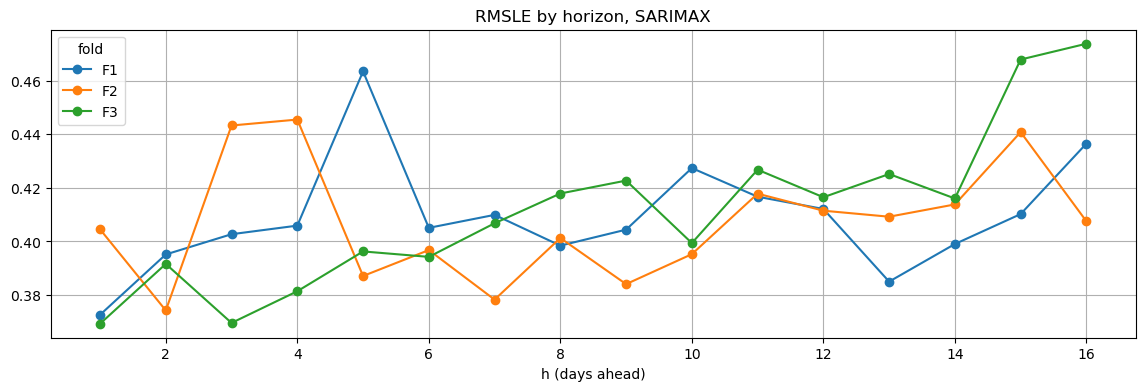

In [7]:
rows = []
for f, cutoff in bt.FOLDS.items():
    o = dev_out[('sarimax', f)].copy()
    o['h'] = (o.date - cutoff).dt.days
    o['fold'] = f
    rows.append(o)
o = pd.concat(rows)
by_h = o.groupby(['h', 'fold']).apply(lambda g: bt.rmsle(g.sales, g.pred), include_groups=False).unstack()
ax = by_h.plot(marker='o', title='RMSLE by horizon, SARIMAX')
ax.set_xlabel('h (days ahead)'); plt.show()

## 5. Residual check on representative series (F1 training data)
If the model captured the structure, the residuals should be white noise (Ljung-Box p > 0.05).

In [8]:
rows = []
for st, fam in [(44, 'GROCERY I'), (44, 'BEVERAGES'), (10, 'PRODUCE'), (30, 'CLEANING')]:
    s = tr[(tr.store_nbr == st) & (tr.family == fam)]
    Xr = np.column_stack([np.log1p(s.onpromotion), s.holiday, s.event, s.closed]).astype(float)
    Xr = Xr[:, Xr.std(axis=0) > 0]
    m = AutoARIMA(season_length=7, ic='bic').fit(np.log1p(s.sales.values.astype(float)), Xr)
    r = pd.Series(m.model_['residuals']).dropna()
    rows.append({'series': f'{st} {fam}', 'model': arima_string(m.model_),
                 'Ljung-Box p (lag 14)': round(acorr_ljungbox(r, lags=[14]).lb_pvalue.iloc[0], 4)})
pd.DataFrame(rows)

,series,model,Ljung-Box p (lag 14)
0,44 GROCERY I,"Regression with ARIMA(2,0,1)(0,1,1)[7] errors",0.2584
1,44 BEVERAGES,"Regression with ARIMA(1,0,0)(0,1,1)[7] errors",0.2937
2,10 PRODUCE,"Regression with ARIMA(2,0,0)(0,1,1)[7] errors",0.6860
3,30 CLEANING,"Regression with ARIMA(1,0,0)(1,0,1)[7] errors",0.0000


## 6. Example series (F3): actual vs forecasts

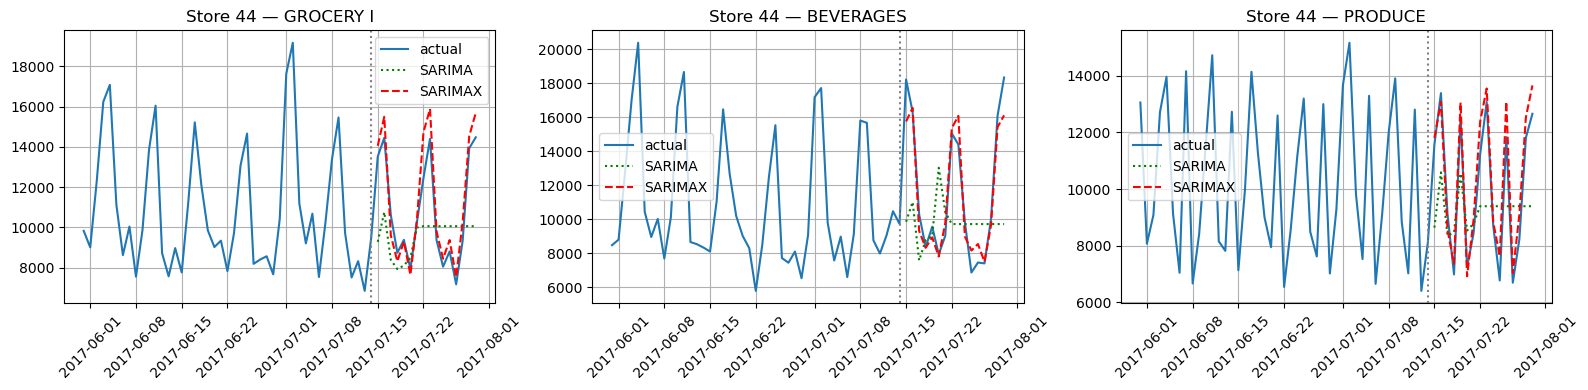

In [9]:
cut3 = bt.FOLDS['F3']
sx3, sa3 = dev_out[('sarimax', 'F3')], dev_out[('sarima', 'F3')]
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, fam in zip(axes, ['GROCERY I', 'BEVERAGES', 'PRODUCE']):
    s = df[(df.store_nbr == 44) & (df.family == fam) & (df.date > cut3 - pd.Timedelta(days=45))
           & (df.date <= cut3 + pd.Timedelta(days=bt.H))]
    ax.plot(s.date, s.sales, label='actual')
    for out, lab, sty in [(sa3, 'SARIMA', 'g:'), (sx3, 'SARIMAX', 'r--')]:
        v = out[(out.store_nbr == 44) & (out.family == fam)]
        ax.plot(v.date, v.pred, sty, label=lab)
    ax.axvline(cut3, color='gray', ls=':')
    ax.set_title(f'Store 44 — {fam}'); ax.tick_params(axis='x', rotation=45); ax.legend()
plt.tight_layout(); plt.show()

## 7. Holdout score (SARIMAX)
Reported once for the final comparison; not used to choose or tune anything. Random-walk holdout: 0.6595.

In [10]:
out_h, s_h = run_cached('sarimax', make_sarimax(True), 'HOLDOUT', bt.HOLDOUT['HOLDOUT'])
print('SARIMAX holdout RMSLE: %.4f   (random walk: 0.6595)' % s_h)

SARIMAX holdout RMSLE: 0.4524   (random walk: 0.6595)


## 8. Test forecast and submission file
Refit on all data up to 2017-08-15 and forecast 2017-08-16 → 2017-08-31.

In [11]:
path = RESULTS + '04_sarimax_TEST.parquet'
history = df[df.date <= bt.TEST_CUTOFF]
future_X = df[df.split == 'test'].drop(columns=['sales'])
if os.path.exists(path):
    pred = pd.read_parquet(path)
else:
    pred = bt.finalize(make_sarimax(True)(history, future_X), history)
    pred.to_parquet(path, index=False)
sub = future_X[bt.K + ['date', 'id']].merge(pred, on=bt.K + ['date'], how='left')
sub = sub[['id', 'pred']].rename(columns={'pred': 'sales'})
sub['id'] = sub.id.astype(int)
sub = sub.sort_values('id')
assert len(sub) == 28512 and sub.sales.notna().all() and (sub.sales >= 0).all()
os.makedirs('submissions', exist_ok=True)
sub.to_csv('submissions/submission_sarimax.csv', index=False)
print('Saved submissions/submission_sarimax.csv', sub.shape)
sub.head()

Saved submissions/submission_sarimax.csv (28512, 2)


,id,sales
0,3000888,3.364118
16,3000889,0.000000
32,3000890,5.794288
48,3000891,2293.603794
64,3000892,0.038810
